# Parte 1 — Dataset y preprocesamiento

Notebook de documentacion, tratamiento de datos y entrenamiento.

## Equipo
- Máximo Alva
- Zahir Jacob

## Configuración del entorno

In [53]:
from pathlib import Path
from dotenv import dotenv_values
from torchvision.datasets.utils import download_file_from_google_drive
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import cv2
from PIL import Image
from tqdm.auto import tqdm
from scipy.stats import spearmanr
import sys
sys.path.insert(0, "src")
from lib.face_pipeline import load_face_app, detect_faces, select_main_face, align_face
import warnings
warnings.filterwarnings("ignore", category=FutureWarning, module="insightface")
ENV = dotenv_values(".env.local.example")

In [54]:
# Inputs
DATA_DIR = Path("./data/raw/CelebA")
IMGS_DIR = DATA_DIR / "Img" / "img_align_celeba"
ANNO_DIR = DATA_DIR / "Anno"

ZIP_PATH = DATA_DIR / "Img" / "img_align_celeba.zip"
IDENTITY_PATH = ANNO_DIR / "identity_CelebA.txt"
ATTR_PATH = ANNO_DIR / "list_attr_celeba.txt"
BBOX_PATH = ANNO_DIR / "list_bbox_celeba.txt"
LANDMARKS_PATH = ANNO_DIR / "list_landmarks_align_celeba.txt"

IMGS_DIR.mkdir(parents=True, exist_ok=True)
ANNO_DIR.mkdir(parents=True, exist_ok=True)

# Outputs
MODELS_DIR = Path("./models")
PROCESSED_DIR = Path("./data/processed")
ALIGNED_DIR = PROCESSED_DIR / "aligned"

DETECTIONS_FILE = PROCESSED_DIR / "detections.csv"
EMBBEDDINGS_FILE = PROCESSED_DIR / "arcface_embeddings.npy"

ALIGNED_DIR.mkdir(parents=True, exist_ok=True)

In [ ]:
# Parámetros de selección del subconjunto
UMBRAL_IDENTITY = 21 # Mínimo de imágenes por identidad
N_IDENTITIES = 1000 # Cantidad de identidades a muestrear al azar
MIN_IMGS_FINAL = 15 # Mínimo de imágenes por identidad después de la limpieza

# Control de calidad
FACE_SIZE = int(ENV["FACE_SIZE"])
MIN_FACE_SIZE = int(ENV["MIN_FACE_SIZE"])

# Detección y alineación (normalización)
DET_SCORE_THRESHOLD = float(ENV["DET_SCORE_THRESHOLD"])
DET_INPUT_SIZE = int(ENV["DET_INPUT_SIZE"])
AMBIGUITY_RATIO = 0.5

# Semilla
SEED = 42

In [19]:
def _to_rgb(img: str | Path | np.ndarray) -> np.ndarray:
    """
    Convierte una imagen BGR (OpenCV) o un archivo a RGB (matplotlib).
    
    Args:
        img: Ruta del archivo de imagen o array de imagen BGR.

    Returns:
        np.ndarray: Imagen en formato RGB.
    """
    # Si la entrada es una ruta de archivo, abrirla y convertirla a RGB
    if isinstance(img, (str, Path)):
        return np.asarray(Image.open(img).convert("RGB"))
    
    # Si la imagen es un array de 2 dimensiones, escala de grises    
    if img.ndim == 2:
        return img
    
    # Si la imagen es un array de 3 dimensiones, convertir de BGR a RGB
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

In [20]:
def show_images(imgs, titles=None, ncols=5, size=(14, 4), suptitle=None):
    """
    Muestra una lista de imágenes en una cuadrícula.
    
    Args:
        imgs: Lista de rutas de imágenes o arrays de imágenes.
        titles: Lista de títulos para cada imagen (opcional).
        ncols: Número de columnas en la cuadrícula.
        size: Tamaño de la figura (ancho, alto).
        suptitle: Título general para la figura (opcional).
    """
    imgs = list(imgs)
    titles = list(titles) if titles is not None else [None] * len(imgs)
    nrows = int(np.ceil(len(imgs) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size[0], size[1]))
    for ax in axes.flat:
        ax.axis("off")
    for ax, img, title in zip(axes.flat, imgs, titles):
        ax.imshow(_to_rgb(img), cmap="gray")
        if title:
            ax.set_title(title, fontsize=10)
    if suptitle:
        fig.suptitle(suptitle, fontsize=14)
    plt.tight_layout()
    plt.show()

In [21]:
def read_header(path: str | Path) -> tuple[str | None, str | None, int | float, int | float, bool]:
    """
    Lee el encabezado de una imagen y devuelve su formato, modo y dimensiones.
    
    Args:
        path (str | Path): Ruta a la imagen.
        
    Returns:
        tuple[str | None, str | None, int | float, int | float, bool]: Tupla con el formato, modo y dimensiones de la imagen.
    """
    try:
        with Image.open(path) as im:
            return im.format, im.mode, im.size[0], im.size[1], True
    except Exception:
        return None, None, np.nan, np.nan, False

## Elección del dataset: CelebA

Para este proyecto de detección y reconocimiento de rostros, hemos seleccionado el dataset **Large-scale CelebFaces Attributes (CelebA)**.

Según su [documentación oficial](https://mmlab.ie.cuhk.edu.hk/projects/CelebA.html):

> CelebFaces Attributes Dataset (CelebA) is a large-scale face attributes dataset with more than **200K** celebrity images, each with **40** attribute annotations. The images in this dataset cover large pose variations and background clutter. CelebA has large diversities, large quantities, and rich annotations, including:
> * **10,177** number of **identities**
> * **202,599** number of **face images**
> * **5 landmark locations** per image
> * **40 binary attributes** annotations per image
>
> The dataset can be employed as the training and test sets for the following computer vision tasks: face attribute recognition, face recognition, face detection, landmark (or facial part) localization, and face editing & synthesis.

Descripción de los archivos a utilizar:

| Archivo | Descripción | Uso en este trabajo |
|---|---|---|
| `img_align_celeba.zip` | Imágenes ya centradas y recortadas, todas de 178×218 | Imágenes de trabajo |
| `identity_CelebA.txt` | Identidad de cada imagen | Etiqueta de clase |
| `list_attr_celeba.txt` | 40 atributos binarios por imagen (`1` / `-1`) anotados a mano | Indicadores aproximados (tienen ruido) para el EDA de expresión, oclusiones y demografía (`Eyeglasses`, `Wearing_Hat`, `Smiling`, `Male`, `Young`, `Pale_Skin`, etc.), para validar la regla de nitidez contra `Blurry` y para cuantificar el sesgo demográfico. **No** se usan como entrada ni como objetivo del modelo |
| `list_landmarks_align_celeba.txt` | Landmarks sobre `img_align_celeba` | Referencia para validar nuestro detector y para el EDA de pose |
| `list_bbox_celeba.txt` | Bounding boxes sobre las imágenes originales sin recortar `img_celeba` (*in the wild*) | Las usamos sólo como medida del tamaño del rostro en la foto de origen |

Elegimos este dataset principalmente debido a su tamaño y cantidad de imágenes por identidad, esto nos brinda la flexibilidad necesaria para poder seleccionar un subconjunto del mismo adaptado especialmente a nuestras necesidades y criterio, garantizando la reproducibilidad en todo el proceso. El dataset incluye variaciones significativas en pose, iluminación, accesorios y expresiones, lo cual provee un entorno desafiante pero realista para entrenar un sistema de reconocimiento facial robusto. El dataset viene acompañado de archivos `.txt` que agregan anotaciones que pueden resultar útiles como coordenadas de bounding boxes, landmarks y otros atributos binarios.

Finalmente, reconocemos como limitación que el dataset arrastra un sesgo demográfico inherente a la industria del entretenimiento (en rangos de edad, tonos de piel, género, etc.), sumado a ciertas disparidades de calidad que abordaremos en las etapas de limpieza.

### Descarga

Descargar archivos `.txt` al directorio `data/CelebA/Anno/`. En caso de no funcionar, descargar manualmente desde el [Drive oficial de Celeba](https://drive.google.com/drive/folders/0B7EVK8r0v71pWEZsZE9oNnFzTm8).

In [22]:
# IDs de los archivos del Drive oficial de CelebA
CELEBA_TXT = [
    ("1_ee_0u7vcNLOfNLegJRHmolfH5ICW-XS", IDENTITY_PATH),
    ("0B7EVK8r0v71pblRyaVFSWGxPY0U", ATTR_PATH),
    ("0B7EVK8r0v71pbThiMVRxWXZ4dU0", BBOX_PATH),
    ("0B7EVK8r0v71pd0FJY3Blby1HUTQ",LANDMARKS_PATH)
]
for file_id, path in CELEBA_TXT:
    download_file_from_google_drive(file_id, root=str(path.parent), filename=path.name)

Descargar `img_align_celeba.zip` al directorio `data/CelebA/Img/` y descomprimir en `img_align_celeba/`. En caso de no funcionar, descargar manualmente desde el [Drive oficial de Celeba](https://drive.google.com/drive/folders/0B7EVK8r0v71pWEZsZE9oNnFzTm8).

In [23]:
# Sólo si la carpeta de imágenes está vacía
if not any(IMGS_DIR.glob("*.jpg")):
    download_file_from_google_drive(
        "0B7EVK8r0v71pZjFTYXZWM3FlRnM",
        root=str(ZIP_PATH.parent),
        filename=ZIP_PATH.name,
        md5="00d2c5bc6d35e252742224ab0c1e8fcb",
    )
    with zipfile.ZipFile(ZIP_PATH) as zf:
        zf.extractall(ZIP_PATH.parent)
    ZIP_PATH.unlink()

### Cargar dataframes

#### Identity

In [24]:
df_identity = pd.read_csv(IDENTITY_PATH, sep=" ", header=None, names=["image_id", "identity"])
df_identity

,image_id,identity
0,000001.jpg,2880
1,000002.jpg,2937
2,000003.jpg,8692
3,000004.jpg,5805
4,000005.jpg,9295
...,...,...
202594,202595.jpg,9761
202595,202596.jpg,7192
202596,202597.jpg,9852
202597,202598.jpg,5570


#### Attr

In [25]:
df_attr = pd.read_csv(ATTR_PATH, sep=r'\s+',skiprows=1)
df_attr.reset_index(inplace=True)
df_attr.rename(columns={df_attr.columns[0]: 'image_id'}, inplace=True)
attr_cols = df_attr.columns.drop("image_id")
df_attr[attr_cols] = df_attr[attr_cols].replace({-1: 0})
df_attr

,image_id,5_o_Clock_Shadow,Arched_Eyebrows,Attractive,Bags_Under_Eyes,Bald,Bangs,Big_Lips,Big_Nose,Black_Hair,...,Sideburns,Smiling,Straight_Hair,Wavy_Hair,Wearing_Earrings,Wearing_Hat,Wearing_Lipstick,Wearing_Necklace,Wearing_Necktie,Young
0,000001.jpg,0,1,1,0,0,0,0,0,0,...,0,1,1,0,1,0,1,0,0,1
1,000002.jpg,0,0,0,1,0,0,0,1,0,...,0,1,0,0,0,0,0,0,0,1
2,000003.jpg,0,0,0,0,0,0,1,0,0,...,0,0,0,1,0,0,0,0,0,1
3,000004.jpg,0,0,1,0,0,0,0,0,0,...,0,0,1,0,1,0,1,1,0,1
4,000005.jpg,0,1,1,0,0,0,1,0,0,...,0,0,0,0,0,0,1,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
202594,202595.jpg,0,0,1,0,0,0,1,0,0,...,0,0,0,0,0,0,1,0,0,1
202595,202596.jpg,0,0,0,0,0,1,1,0,0,...,0,1,1,0,0,0,0,0,0,1
202596,202597.jpg,0,0,0,0,0,0,0,0,1,...,0,1,0,0,0,0,0,0,0,1
202597,202598.jpg,0,1,1,0,0,0,1,0,1,...,0,1,0,1,1,0,1,0,0,1


#### Bbox

In [26]:
df_bbox = pd.read_csv(BBOX_PATH, sep=r'\s+', skiprows=1)
df_bbox.rename(columns={'x_1': 'orig_bbox_x1', 'y_1': 'orig_bbox_y1', 'width': 'orig_bbox_width', 'height': 'orig_bbox_height'}, inplace=True)
df_bbox

,image_id,orig_bbox_x1,orig_bbox_y1,orig_bbox_width,orig_bbox_height
0,000001.jpg,95,71,226,313
1,000002.jpg,72,94,221,306
2,000003.jpg,216,59,91,126
3,000004.jpg,622,257,564,781
4,000005.jpg,236,109,120,166
...,...,...,...,...,...
202594,202595.jpg,1381,91,221,306
202595,202596.jpg,137,129,114,158
202596,202597.jpg,53,76,91,126
202597,202598.jpg,195,28,91,126


#### Landmarks

In [27]:
df_landmarks = pd.read_csv(LANDMARKS_PATH, sep=r'\s+', skiprows=1)
df_landmarks.reset_index(inplace=True)
df_landmarks.rename(columns={df_landmarks.columns[0]: 'image_id'}, inplace=True)
df_landmarks

,image_id,lefteye_x,lefteye_y,righteye_x,righteye_y,nose_x,nose_y,leftmouth_x,leftmouth_y,rightmouth_x,rightmouth_y
0,000001.jpg,69,109,106,113,77,142,73,152,108,154
1,000002.jpg,69,110,107,112,81,135,70,151,108,153
2,000003.jpg,76,112,104,106,108,128,74,156,98,158
3,000004.jpg,72,113,108,108,101,138,71,155,101,151
4,000005.jpg,66,114,112,112,86,119,71,147,104,150
...,...,...,...,...,...,...,...,...,...,...,...
202594,202595.jpg,69,111,108,111,89,140,73,151,104,153
202595,202596.jpg,67,112,110,112,85,141,66,150,110,150
202596,202597.jpg,69,111,107,111,92,137,68,151,109,153
202597,202598.jpg,69,111,108,111,90,137,71,153,106,151


### Unir dataframes

In [28]:
# Unificar todos los dataframes usando 'image_id' como primary key
df_celeba = df_identity.merge(df_attr, on='image_id', how='inner')
df_celeba = df_celeba.merge(df_bbox, on='image_id', how='inner')
df_celeba = df_celeba.merge(df_landmarks, on='image_id', how='inner')
df_celeba

,image_id,identity,5_o_Clock_Shadow,Arched_Eyebrows,Attractive,Bags_Under_Eyes,Bald,Bangs,Big_Lips,Big_Nose,...,lefteye_x,lefteye_y,righteye_x,righteye_y,nose_x,nose_y,leftmouth_x,leftmouth_y,rightmouth_x,rightmouth_y
0,000001.jpg,2880,0,1,1,0,0,0,0,0,...,69,109,106,113,77,142,73,152,108,154
1,000002.jpg,2937,0,0,0,1,0,0,0,1,...,69,110,107,112,81,135,70,151,108,153
2,000003.jpg,8692,0,0,0,0,0,0,1,0,...,76,112,104,106,108,128,74,156,98,158
3,000004.jpg,5805,0,0,1,0,0,0,0,0,...,72,113,108,108,101,138,71,155,101,151
4,000005.jpg,9295,0,1,1,0,0,0,1,0,...,66,114,112,112,86,119,71,147,104,150
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
202594,202595.jpg,9761,0,0,1,0,0,0,1,0,...,69,111,108,111,89,140,73,151,104,153
202595,202596.jpg,7192,0,0,0,0,0,1,1,0,...,67,112,110,112,85,141,66,150,110,150
202596,202597.jpg,9852,0,0,0,0,0,0,0,0,...,69,111,107,111,92,137,68,151,109,153
202597,202598.jpg,5570,0,1,1,0,0,0,1,0,...,69,111,108,111,90,137,71,153,106,151


## Análisis exploratorio (EDA)

### Imágenes por identidad y desbalance de clases


Este análisis lo realizamos sobre sobre el dataset completo. Es la información que necesitamos para poder decidir sobre qué subconjunto trabajar y que umbral utilizar para corregir el desbalance de imágenes por identidad.

In [29]:
print(f"Total de imágenes en {IMGS_DIR}: {len(list(IMGS_DIR.glob('*.jpg')))}")
print(f"Total de registros en dataframe: {len(df_celeba)}")

Total de imágenes en data\raw\CelebA\Img\img_align_celeba: 202599
Total de registros en dataframe: 202599


In [30]:
print(f"Total de identidades únicas: {df_celeba['identity'].nunique()}")

Total de identidades únicas: 10177


In [31]:
identity_counts = df_celeba["identity"].value_counts()
print(identity_counts)

identity
2820    35
3782    35
3227    35
3745    34
3699    34
        ..
4273     1
2708     1
8565     1
8585     1
7778     1
Name: count, Length: 10177, dtype: int64


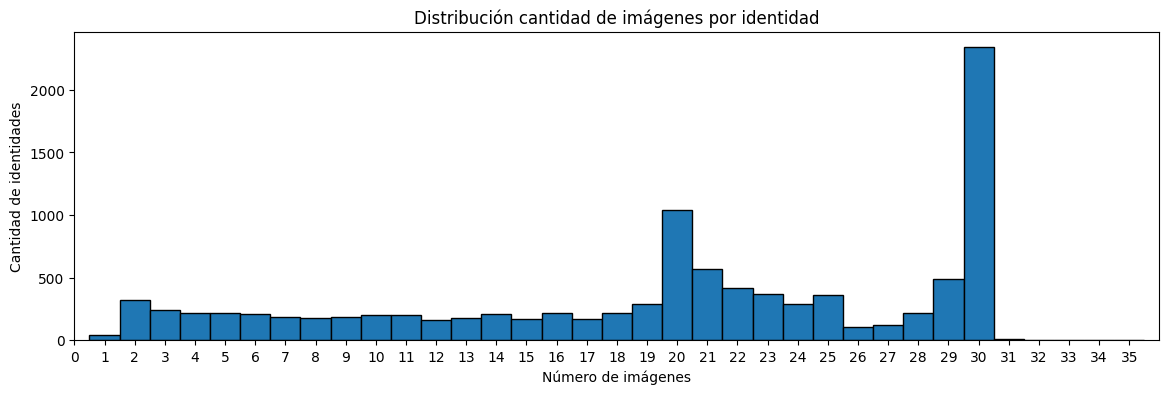

In [32]:
# Gráfico de distribución
identity_counts_max = identity_counts.max()
plt.figure(figsize=(14, 4))
bins = np.arange(1, identity_counts_max + 2) - 0.5
plt.hist(identity_counts, bins=bins, edgecolor='black')
plt.xlim(0, identity_counts_max + 1)
plt.xticks(range(0, identity_counts_max + 1))
plt.title("Distribución cantidad de imágenes por identidad")
plt.xlabel("Número de imágenes")
plt.ylabel("Cantidad de identidades")
plt.show()

In [33]:
print(identity_counts.describe())

count    10177.000000
mean        19.907537
std          8.925916
min          1.000000
25%         13.000000
50%         21.000000
75%         29.000000
max         35.000000
Name: count, dtype: float64


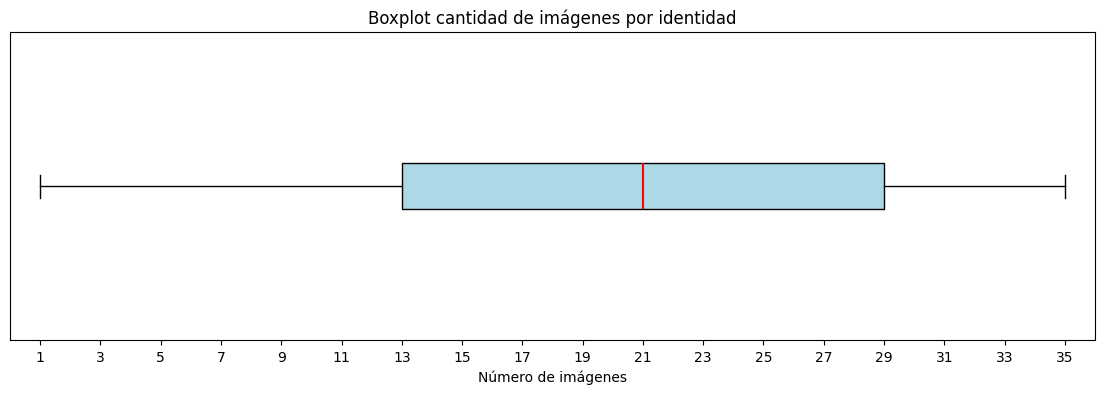

In [34]:
# Boxplot
plt.figure(figsize=(14, 4))
plt.boxplot(identity_counts, vert=False, patch_artist=True, boxprops=dict(facecolor='lightblue', color='black'), medianprops=dict(color='red', linewidth=1.5))
plt.xlim(0, identity_counts_max + 1)
plt.xticks(range(1, identity_counts_max + 1, 2))
plt.title("Boxplot cantidad de imágenes por identidad")
plt.xlabel("Número de imágenes")
plt.gca().axes.get_yaxis().set_visible(False)
plt.show()

In [35]:
n_ids = len(identity_counts)
rows = []
for t in [1, 5, 10, 15, 20, 21, 25, 30]:
    kept = identity_counts[identity_counts >= t]
    rows.append({
        "umbral (≥)": t,
        "identidades": len(kept),
        "% identidades": 100 * len(kept) / n_ids,
        "imágenes": int(kept.sum()),
        "% imágenes": 100 * kept.sum() / identity_counts.sum(),
        "desbalance máx/mín": kept.max() / kept.min(),
    })
df_thr = pd.DataFrame(rows).round(2)
df_thr

,umbral (≥),identidades,% identidades,imágenes,% imágenes,desbalance máx/mín
0,1,10177,100.00,202599,100.00,35.00
1,5,9343,91.81,200288,98.86,7.00
2,10,8369,82.23,193569,95.54,3.50
3,15,7417,72.88,182152,89.91,2.33
4,20,6348,62.38,163749,80.82,1.75
5,21,5304,52.12,142869,70.52,1.67
6,25,3661,35.97,106339,52.49,1.40
7,30,2360,23.19,70838,34.96,1.17


### Elección del umbral de imágenes por identidad y el tamaño del subconjunto

Teniendo en cuenta que el enunciado recomienda un mínimo de 10 a 20 imágenes por persona, elegimos establecer el `UMBRAL_IDENTITY = 21` (umbral de imágenes por identidad), lo que deja margen para la limpieza posterior, que va a descartar algunas imágenes; por ello, al final del proceso exigimos `MIN_IMGS_FINAL = 15`. Al ser 21 la mediana de la distribución, nos estamos quedando con la mitad de las identidades que más imágenes tienen. Además el desbalance desciende de 35 a ≈ 1,67, por lo que casi no hace falta re-balancear durante el entrenamiento.

Cada identidad de entrenamiento se divide 80/10/10 entre `train`, `val_closed` y `test_closed`: con 21 imágenes quedan unas 17 para entrenar y al menos 2 para evaluar.

Con este umbral, las identidades elegibles superan las 5.000, con más de 140.000 imágenes. Decidimos quedarnos con `N_IDENTITIES = 1000`, elegidas al azar con semilla fija, del orden de 28.000 imágenes. Consideramos que es un tamaño suficiente para entrenar una CNN de clasificación con unas 700 clases y evaluar sobre unas 150 identidades nunca vistas, y reduce considerablemente el costo computacional de la detección, la alineación y la extracción de embeddings.

In [36]:
eligible_ids = identity_counts[identity_counts >= UMBRAL_IDENTITY].index.to_numpy()
rng_subset = np.random.default_rng(SEED)

if N_IDENTITIES is not None and N_IDENTITIES < len(eligible_ids):
    selected_ids = np.sort(rng_subset.choice(eligible_ids, size=N_IDENTITIES, replace=False))
else:
    selected_ids = np.sort(eligible_ids)

df = df_celeba[df_celeba["identity"].isin(selected_ids)].reset_index(drop=True).copy()
df["src_path"] = df["image_id"].map(lambda f: str(IMGS_DIR / f))

print(f"Identidades elegibles (≥ {UMBRAL_IDENTITY} imágenes): {len(eligible_ids)}")
print(f"Subconjunto: {df['identity'].nunique()} identidades, {len(df)} imágenes")
df["identity"].value_counts().describe().round(2)

Identidades elegibles (≥ 21 imágenes): 5304
Subconjunto: 1000 identidades, 26917 imágenes


count    1000.00
mean       26.92
std         3.46
min        21.00
25%        23.00
50%        29.00
75%        30.00
max        30.00
Name: count, dtype: float64

### Muestra visual

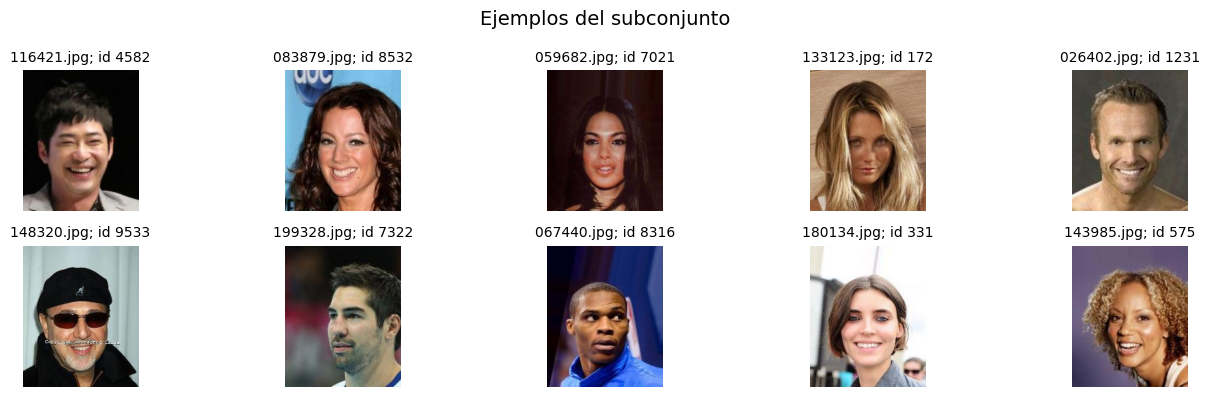

In [37]:
# 8 imágenes al azar del subconjunto
sample_df = df.sample(n=10, random_state=SEED).reset_index(drop=True)
show_images(sample_df["src_path"], titles=[f"{r.image_id}; id {r.identity}" for r in sample_df.itertuples()], suptitle="Ejemplos del subconjunto")

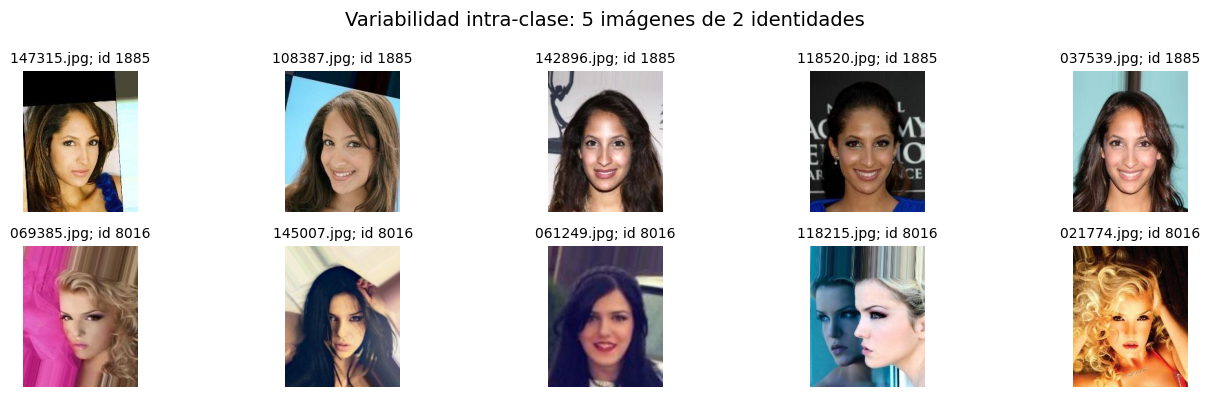

In [38]:
# Variabilidad intra-clase: 5 imágenes de 2 identidades
show_ids = np.random.default_rng(SEED).choice(df["identity"].unique(), size=2, replace=False)
imgs, titles = [], []
for ident in show_ids:
    rows_id = df[df["identity"] == ident].sample(n=5, random_state=SEED)
    imgs += rows_id["src_path"].tolist()
    titles += [f"{r.image_id}; id {r.identity}" for r in rows_id.itertuples()]
show_images(imgs, titles=titles, suptitle="Variabilidad intra-clase: 5 imágenes de 2 identidades")

### Formato, canales e integridad de archivos

Leemos el encabezado de cada archivo.

In [39]:
hdr = pd.DataFrame([read_header(p) for p in tqdm(df["src_path"], desc="encabezados")], columns=["fmt", "mode", "img_w", "img_h", "header_ok"], index=df.index)
df = df.drop(columns=hdr.columns, errors="ignore").join(hdr)

print("Formato   :", df["fmt"].value_counts(dropna=False).to_dict())
print("Modo      :", df["mode"].value_counts(dropna=False).to_dict())
print("Extensión :", df["src_path"].map(lambda p: Path(p).suffix.lower()).value_counts().to_dict())
print("Ilegibles :", int((~df["header_ok"]).sum()))
df.groupby(["img_w", "img_h"]).size().rename("imágenes").sort_values(ascending=False).head()

encabezados: 100%|██████████| 26917/26917 [00:12<00:00, 2119.52it/s]


Formato   : {'JPEG': 26917}
Modo      : {'RGB': 26917}
Extensión : {'.jpg': 26917}
Ilegibles : 0


img_w  img_h
178    218      26917
Name: imágenes, dtype: int64

Las 26.917 imágenes del subconjunto son archivos JPEG en modo RGB, con extensión `.jpg`, y todas tienen la misma resolución de 178×218 píxeles. No encontramos archivos ilegibles.

Esta verificación sólo lee el encabezado de cada archivo; la decodificación completa de la imagen se comprueba en la etapa de detección, donde una imagen que no se pueda abrir se descarta como corrupta.

Que todas las imágenes estén en modo RGB no significa que todas sean a color, una foto en blanco y negro guardada como RGB tiene los tres canales iguales. Las detectaremos más adelante a partir de la saturación.

Como CelebA entrega todas las imágenes recortadas al mismo tamaño, la resolución del archivo no permite distinguir imágenes de mejor o peor calidad. Por eso, en la sección siguiente analizaremos el tamaño que tenía el rostro en la foto original.

### Resoluciones y tamaño del rostro

Como todas las imágenes de `img_align_celeba` tienen el mismo tamaño (178×218, relación de aspecto ≈ 0,82), la resolución del archivo no nos dice nada sobre su calidad. Lo que importa es cuánto medía el rostro en la foto original, si allí medía 40 px, CelebA la amplió para llevarla a 178×218 perdiendo detalle real. Para medirlo usaremos el **ancho del rostro en la foto original** (`orig_bbox_width` de `list_bbox_celeba.txt`), comparado con `MIN_FACE_PX` y con `FACE_SIZE`.

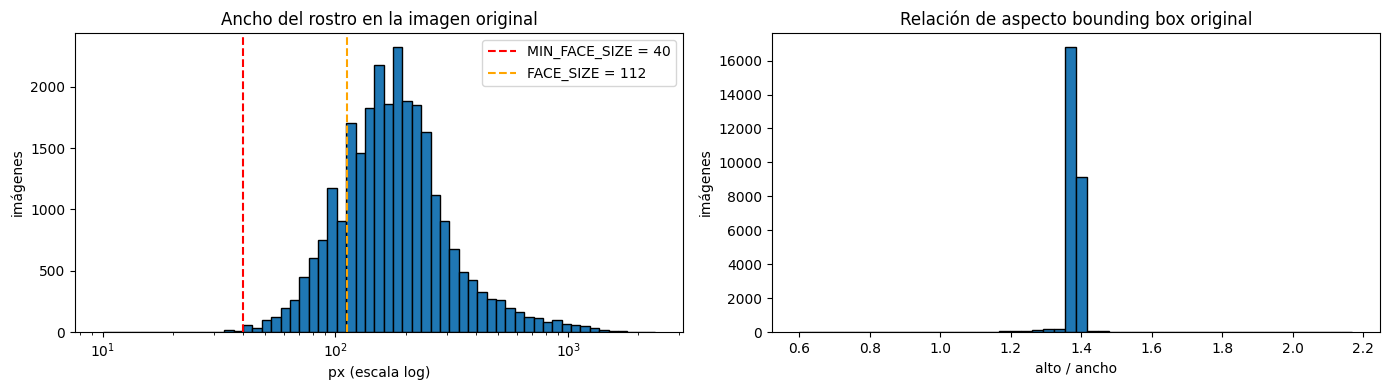

Ancho del rostro en la imagen original: mediana 174 px, mínimo 10 px, máximo 2366 px


In [40]:
w = df["orig_bbox_width"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(w, bins=np.logspace(np.log10(max(w.min(), 1)), np.log10(w.max()), 60), edgecolor="black")
axes[0].set_xscale("log")
axes[0].axvline(MIN_FACE_SIZE, color="red", ls="--", label=f"MIN_FACE_SIZE = {MIN_FACE_SIZE}")
axes[0].axvline(FACE_SIZE, color="orange", ls="--", label=f"FACE_SIZE = {FACE_SIZE}")
axes[0].set(title="Ancho del rostro en la imagen original", xlabel="px (escala log)", ylabel="imágenes")
axes[0].legend()

axes[1].hist(df["orig_bbox_height"] / w, bins=50, edgecolor="black")
axes[1].set(title="Relación de aspecto bounding box original", xlabel="alto / ancho", ylabel="imágenes")

plt.tight_layout()
plt.show()

print(f"Ancho del rostro en la imagen original: mediana {w.median():.0f} px, mínimo {w.min()} px, máximo {w.max()} px")

In [41]:
# Rostros chicos
print(f"Rostros < 20 px: {(w < 20).sum()} ({100 * (w < 20).mean():.2f}%)")
print(f"Rostros < {MIN_FACE_SIZE} px: {(w < MIN_FACE_SIZE).sum()} ({100 * (w < MIN_FACE_SIZE).mean():.2f}%)")
print(f"Rostros < {FACE_SIZE} px: {(w < FACE_SIZE).sum()} ({100 * (w < FACE_SIZE).mean():.2f}%)")
print(f"Rostros >= {FACE_SIZE} px: {(w >= FACE_SIZE).sum()} ({100 * (w >= FACE_SIZE).mean():.2f}%)")

Rostros < 20 px: 7 (0.03%)
Rostros < 40 px: 40 (0.15%)
Rostros < 112 px: 4704 (17.48%)
Rostros >= 112 px: 22213 (82.52%)


El ancho del rostro en la imagen original es muy asimétrico, con una cola larga hacia los rostros grandes: la mediana es de 174 px y los valores van de 10 a 2.366 px. El 82,52% de las imágenes (22.213) proviene de rostros de al menos 112 px, que al llevarse a `FACE_SIZE` se reducen sin perder detalle. El 17,48% restante (4.704 imágenes) corresponde a rostros más chicos, que CelebA amplió y que tienen menos detalle real del que aparenta su resolución. Entre ellos, los rostros realmente chicos son muy pocos: 40 imágenes (0,15%) miden menos de 40 px, y sólo 7 (0,03%) menos de 20 px.

La relación de aspecto de las cajas es casi constante (alto/ancho ≈ 1,39), salvo en algunos casos.

Fijamos `MIN_FACE_SIZE = 40`, el mismo valor que usa la app. En este dataset, subir el mínimo de 20 a 40 px descarta sólo 33 imágenes más; el valor importa sobre todo en la app, donde un rostro de 20 px ampliado a 112×112 produce un embedding poco confiable.

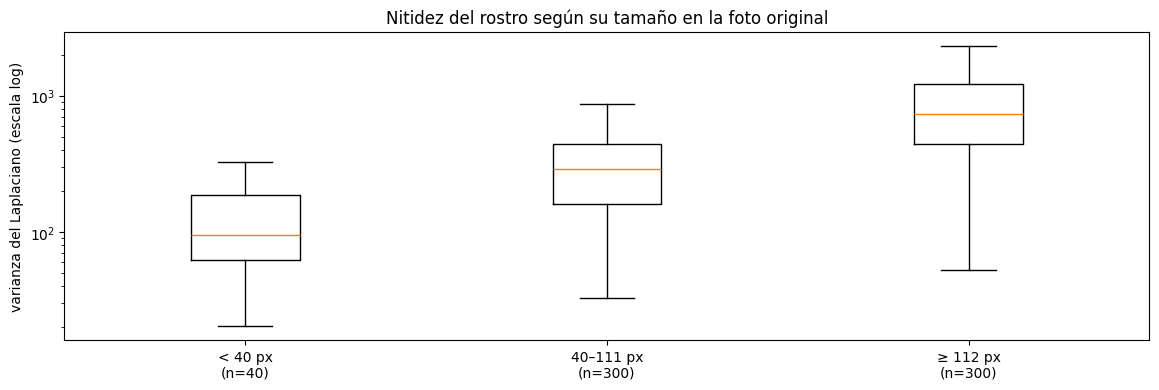

Correlación de Spearman entre tamaño original y nitidez: 0.68 (p = 2.6e-86)


In [42]:
size_labels = [f"< {MIN_FACE_SIZE} px", f"{MIN_FACE_SIZE}–{FACE_SIZE - 1} px", f"≥ {FACE_SIZE} px"]
df["orig_face_size"] = pd.cut(w, bins=[0, MIN_FACE_SIZE, FACE_SIZE, np.inf], labels=size_labels, right=False)

# Muestra de hasta 300 imágenes por grupo (el grupo < 40 px tiene sólo 40)
parts = [g.sample(n=min(300, len(g)), random_state=SEED) for _, g in df.groupby("orig_face_size", observed=True)]
sharp = pd.concat(parts)
sharp["sharpness"] = [
    cv2.Laplacian(cv2.imread(p, cv2.IMREAD_GRAYSCALE)[75:185, 45:133], cv2.CV_64F).var()
    for p in sharp["src_path"]
]

groups = [sharp.loc[sharp["orig_face_size"] == lab, "sharpness"] for lab in size_labels]
plt.figure(figsize=(14, 4))
plt.boxplot(groups, tick_labels=[f"{lab}\n(n={len(g)})" for lab, g in zip(size_labels, groups)], showfliers=False)
plt.yscale("log")
plt.ylabel("varianza del Laplaciano (escala log)")
plt.title("Nitidez del rostro según su tamaño en la foto original")
plt.show()

rho, pval = spearmanr(sharp["orig_bbox_width"], sharp["sharpness"])
print(f"Correlación de Spearman entre tamaño original y nitidez: {rho:.2f} (p = {pval:.1e})")

Para verificar que los rostros pequeños en la imagen original efectivamente tienen menos detalle, medimos la nitidez de la zona del rostro (varianza del Laplaciano) en una muestra de cada grupo. La mediana pasa de ≈ 95 en los rostros de menos de 40 px a ≈ 290 entre 40 y 111 px y a ≈ 750 en los de al menos 112 px, con una correlación de Spearman de 0,68 entre el tamaño original y la nitidez. Esto respalda descartar los rostros menores a `MIN_FACE_SIZE`. El grupo intermedio también es menos nítido, pero representa el 17% del dataset, así que no lo descartamos por tamaño. Como los grupos se superponen, el tamaño original no alcanza para decidir la calidad de una imagen, y por eso el control de calidad mide la nitidez directamente sobre cada recorte.

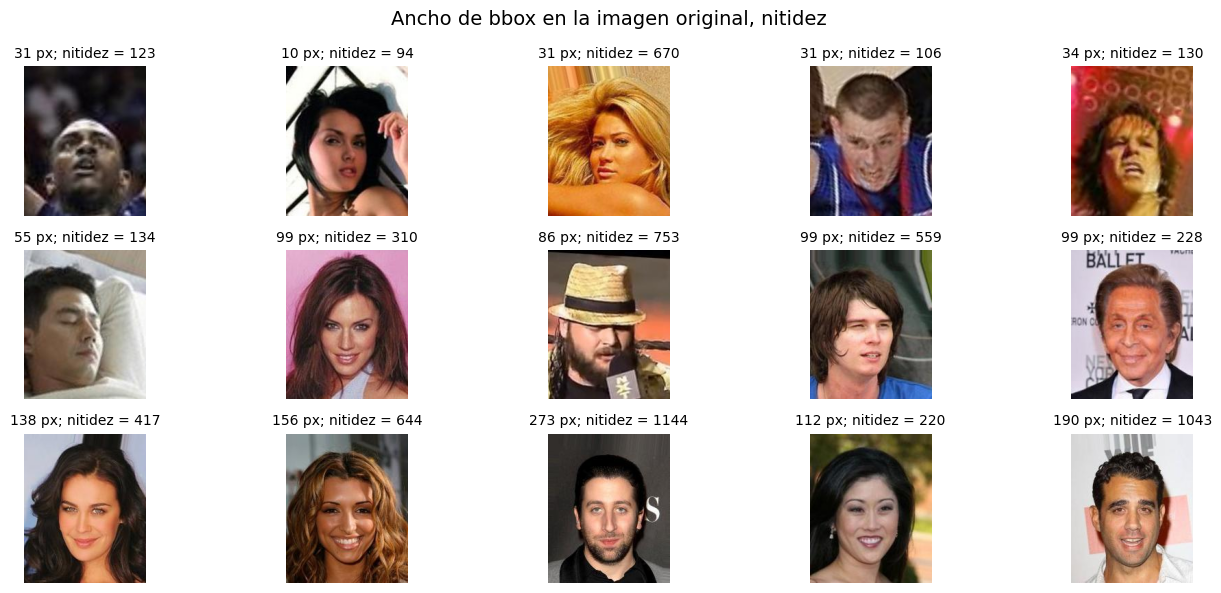

In [43]:
imgs, titles = [], []
for lab in size_labels:
    rows_g = sharp[sharp["orig_face_size"] == lab].sample(n=5, random_state=SEED)
    imgs += rows_g["src_path"].tolist()
    titles += [f"{r.orig_bbox_width} px; nitidez = {r.sharpness:.0f}" for r in rows_g.itertuples()]

show_images(imgs, titles=titles, ncols=5, size=(14, 6), suptitle=f"Ancho de bbox en la imagen original, nitidez")

La grilla confirma visualmente la tendencia, los rostros que medían menos de 40 px en el original se ven pixelados o borrosos, mientras que los de al menos 112 px tienen buena calidad.

### Variaciones

Estas variaciones son las que el modelo tiene que tolerar para reconocer a una misma persona en fotos distintas. La iluminación y el color los medimos directamente sobre los píxeles de la zona del rostro, en una muestra. La pose la estimamos a partir de los landmarks de CelebA, y la expresión y las oclusiones a partir de los atributos anotados a mano del dataset.

#### Iluminación

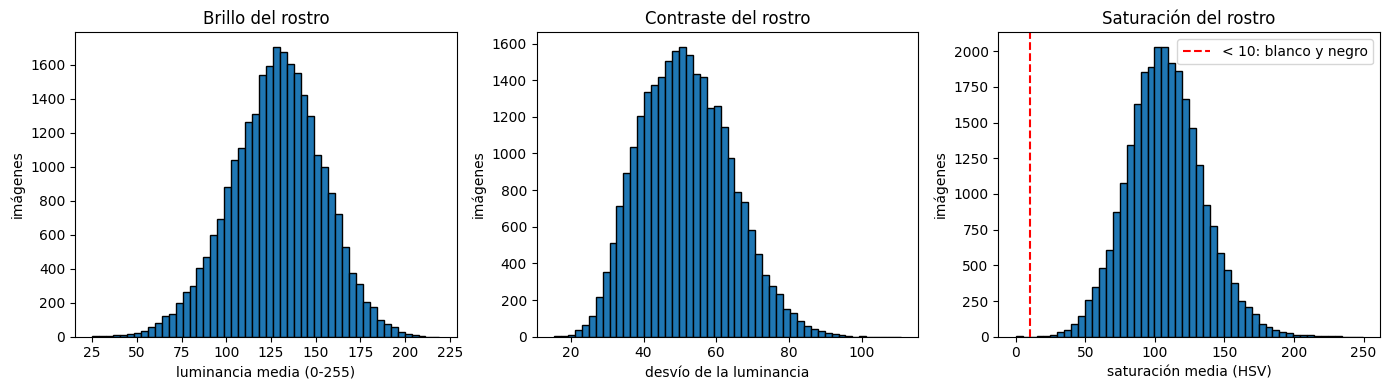

Brillo: mediana 129, mínimo 25, máximo 219
Contraste: mediana 51, mínimo 15, máximo 111
Saturacion: mediana 107, mínimo 0, máximo 249
Blanco y negro: 8 de 26917 (0.03%)


In [44]:
# Brillo (media), contraste (desvío) y saturación de la zona del rostro
stats = []
for p in df["src_path"]:
    face = cv2.imread(p)[75:185, 45:133]
    gray = cv2.cvtColor(face, cv2.COLOR_BGR2GRAY)
    sat = cv2.cvtColor(face, cv2.COLOR_BGR2HSV)[..., 1]
    stats.append((gray.mean(), gray.std(), sat.mean()))
df[["brillo", "contraste", "saturacion"]] = np.array(stats)
df["blanco_negro"] = df["saturacion"] < 10

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].hist(df["brillo"], bins=50, edgecolor="black")
axes[0].set(title="Brillo del rostro", xlabel="luminancia media (0-255)", ylabel="imágenes")
axes[1].hist(df["contraste"], bins=50, edgecolor="black")
axes[1].set(title="Contraste del rostro", xlabel="desvío de la luminancia", ylabel="imágenes")
axes[2].hist(df["saturacion"], bins=50, edgecolor="black")
axes[2].axvline(10, color="red", ls="--", label="< 10: blanco y negro")
axes[2].set(title="Saturación del rostro", xlabel="saturación media (HSV)", ylabel="imágenes")
axes[2].legend()
plt.tight_layout()
plt.show()

for col in ["brillo", "contraste", "saturacion"]:
    print(f"{col.capitalize()}: mediana {df[col].median():.0f}, mínimo {df[col].min():.0f}, máximo {df[col].max():.0f}")
print(f"Blanco y negro: {df['blanco_negro'].sum()} de {len(df)} ({100 * df['blanco_negro'].mean():.2f}%)")

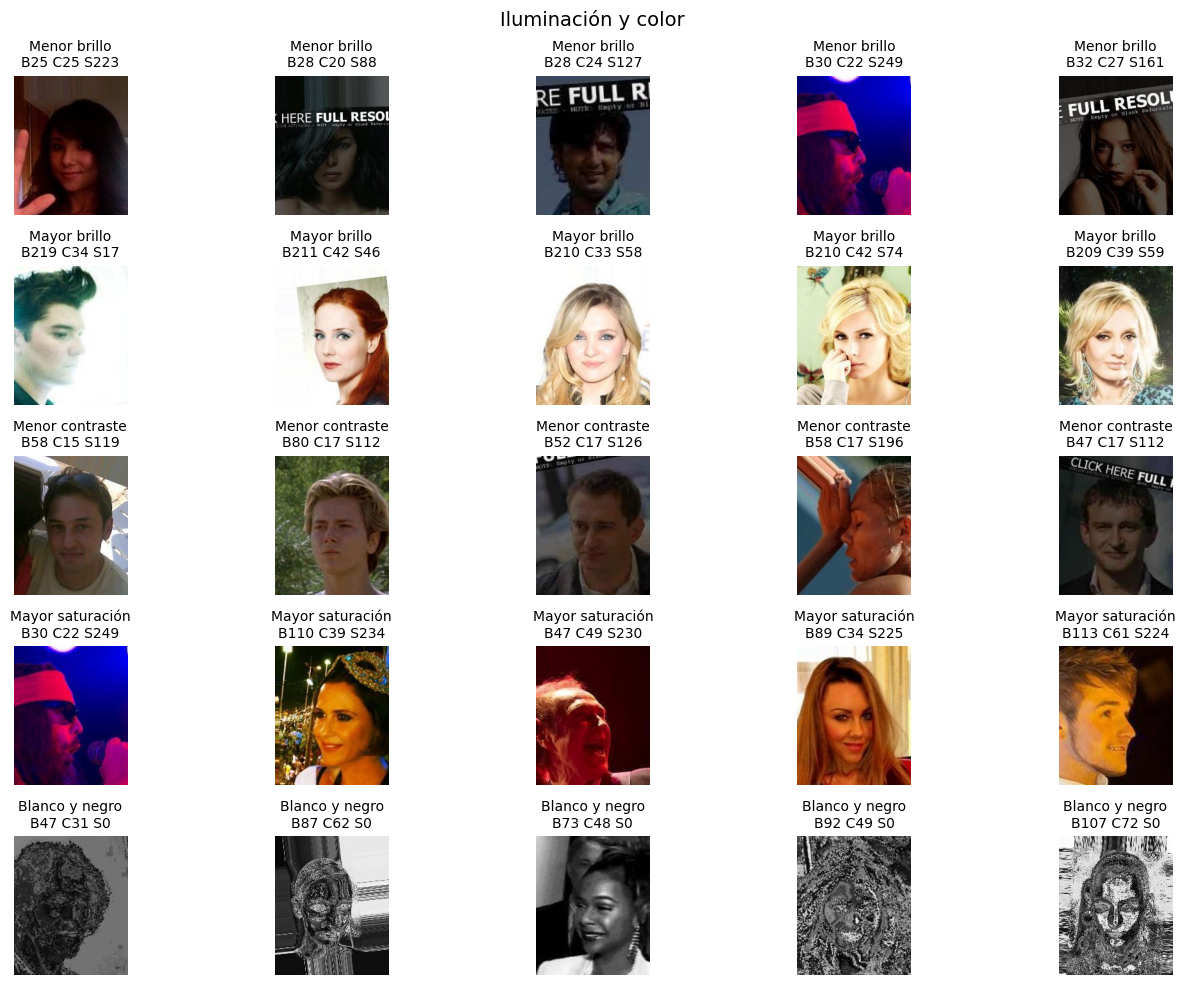

In [45]:
casos = {
    "Menor brillo": df.nsmallest(5, "brillo"),
    "Mayor brillo": df.nlargest(5, "brillo"),
    "Menor contraste": df.nsmallest(5, "contraste"),
    "Mayor saturación": df.nlargest(5, "saturacion"),
    "Blanco y negro": df[df["blanco_negro"]].sample(n=5, random_state=SEED),
}
imgs, titles = [], []
for nombre, sub in casos.items():
    imgs += sub["src_path"].tolist()
    titles += [f"{nombre}\nB{r.brillo:.0f} C{r.contraste:.0f} S{r.saturacion:.0f}" for r in sub.itertuples()]

show_images(imgs, titles=titles, size=(14, 10), suptitle="Iluminación y color")

Sólo 8 imágenes (0,03%) tienen saturación menor a 10. Al inspeccionarlas, la mayoría no son fotografías en blanco y negro, sino imágenes con alguna especie de filtro, que no representan ningún caso que la app vaya a recibir. Por eso decidimos descartarlas en el control de calidad con una regla de saturación mínima. Perder alguna foto en blanco y negro legítima no tiene impacto con esta cantidad, y la robustez a imágenes sin color se cubre con la conversión a escala de grises de la augmentation.

#### Pose

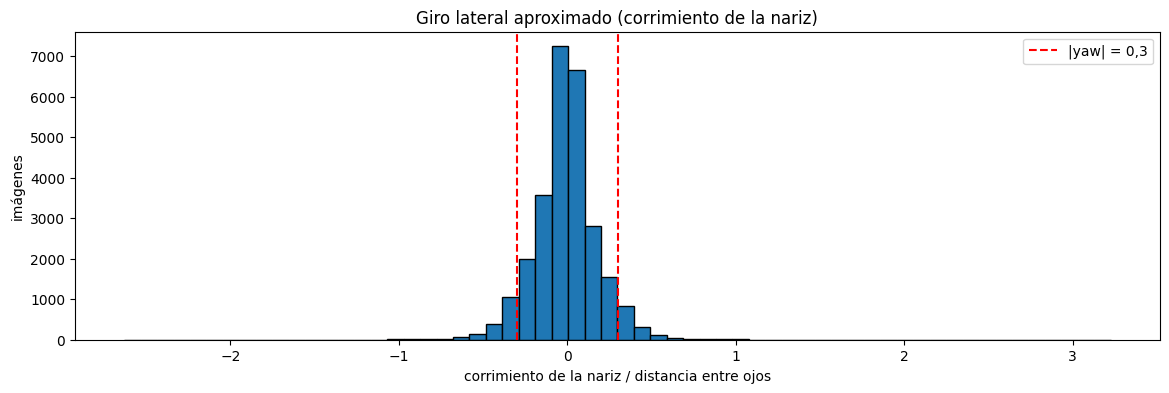

|yaw| > 0,3 (giro marcado): 2794 (10.38%)


In [46]:
interocular_distance = np.hypot(df["righteye_x"] - df["lefteye_x"], df["righteye_y"] - df["lefteye_y"])
df["yaw"] = (df["nose_x"] - (df["lefteye_x"] + df["righteye_x"]) / 2) / interocular_distance

plt.figure(figsize=(14, 4))
plt.hist(df["yaw"], bins=60, edgecolor="black")
plt.axvline(-0.3, color="red", ls="--")
plt.axvline(0.3, color="red", ls="--", label="|yaw| = 0,3")
plt.title("Giro lateral aproximado (corrimiento de la nariz)")
plt.xlabel("corrimiento de la nariz / distancia entre ojos")
plt.ylabel("imágenes")
plt.legend()
plt.show()

print(f"|yaw| > 0,3 (giro marcado): {(df['yaw'].abs() > 0.3).sum()} ({100 * (df['yaw'].abs() > 0.3).mean():.2f}%)")

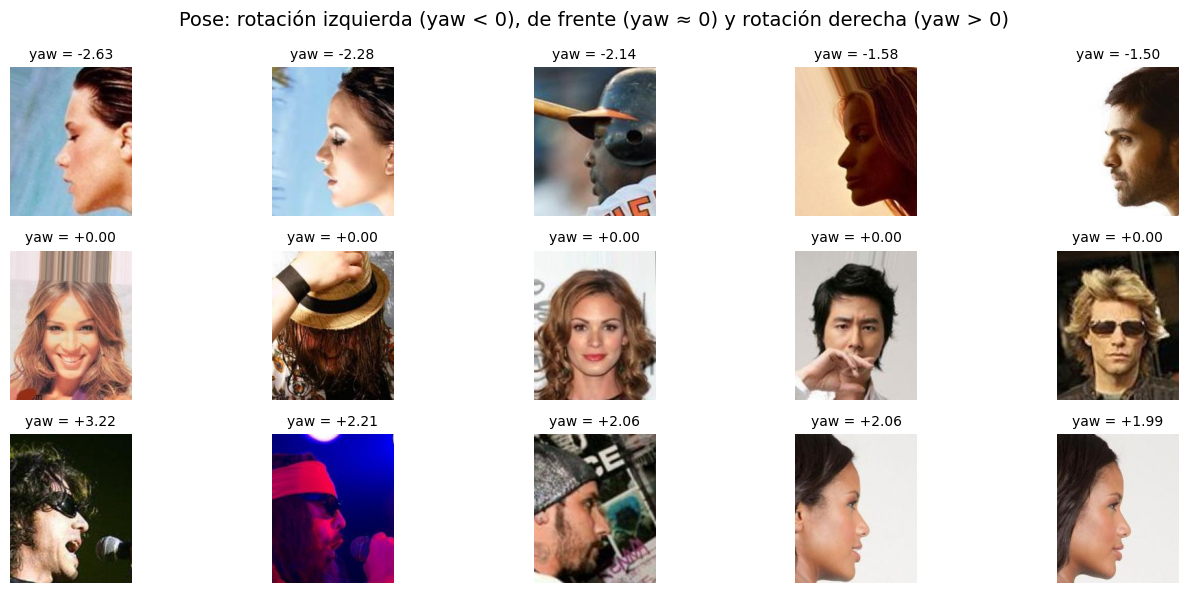

In [47]:
pose = {
    "Rotación izquierda (yaw negativo)": df.nsmallest(5, "yaw"),
    "De frente (yaw ≈ 0)": df.loc[df["yaw"].abs().nsmallest(5).index],
    "Rotación derecha (yaw positivo)": df.nlargest(5, "yaw"),
}

imgs, titles = [], []
for nombre, sub in pose.items():
    imgs += sub["src_path"].tolist()
    titles += [f"yaw = {v:+.2f}" for v in sub["yaw"]]

show_images(imgs, titles=titles, ncols=5, size=(14, 6), suptitle="Pose: rotación izquierda (yaw < 0), de frente (yaw ≈ 0) y rotación derecha (yaw > 0)")

#### Expresión y oclusiones

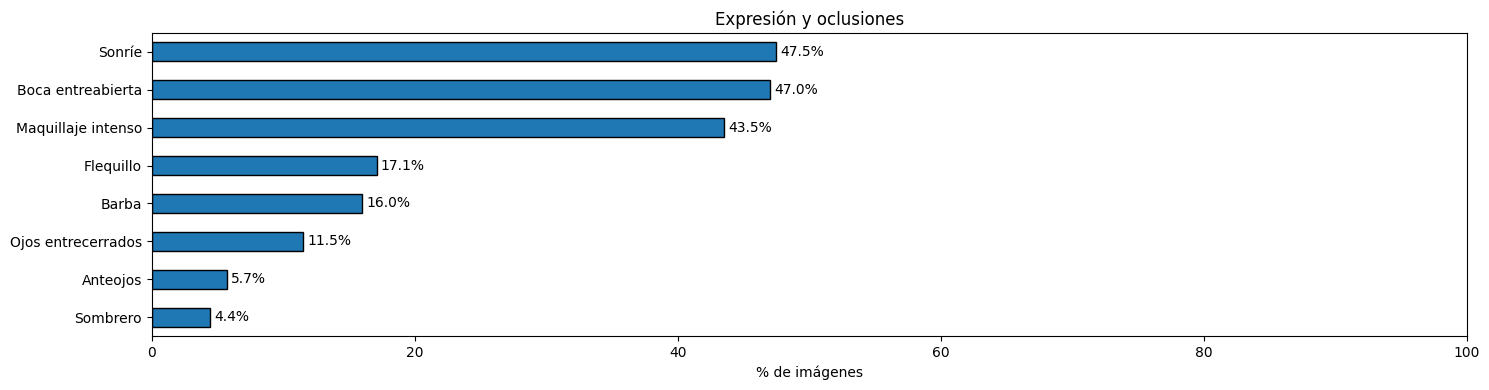

In [48]:
atributos = pd.DataFrame({
    "Sonríe": df["Smiling"],
    "Boca entreabierta": df["Mouth_Slightly_Open"],
    "Ojos entrecerrados": df["Narrow_Eyes"],
    "Anteojos": df["Eyeglasses"],
    "Sombrero": df["Wearing_Hat"],
    "Flequillo": df["Bangs"],
    "Barba": 1 - df["No_Beard"],
    "Maquillaje intenso": df["Heavy_Makeup"]
})
prevalencia = (atributos.mean() * 100).round(1).sort_values()

ax = prevalencia.plot.barh(figsize=(15, 4), edgecolor="black")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.set_xlim(0, 100)
ax.set(title="Expresión y oclusiones", xlabel="% de imágenes")
plt.tight_layout()
plt.show()

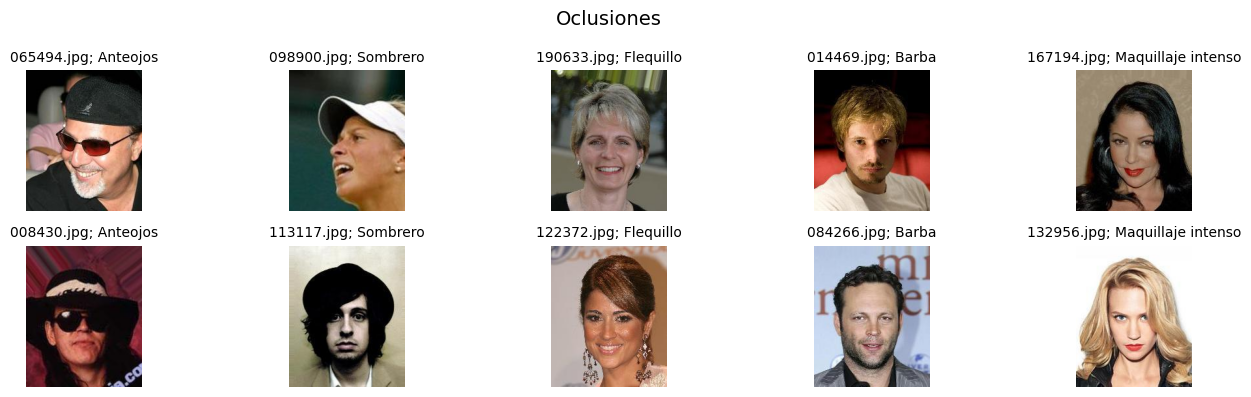

In [49]:
nombres = ["Anteojos", "Sombrero", "Flequillo", "Barba", "Maquillaje intenso"]
muestras = {nombre: df[atributos[nombre] == 1].sample(n=2, random_state=SEED) for nombre in nombres}

imgs, titles = [], []
for fila in range(2):
    for nombre in nombres:
        r = muestras[nombre].iloc[fila]
        imgs.append(r["src_path"])
        titles.append(f"{r['image_id']}; {nombre}")

show_images(imgs, titles=titles, ncols=len(nombres), size=(14, 4), suptitle="Oclusiones")

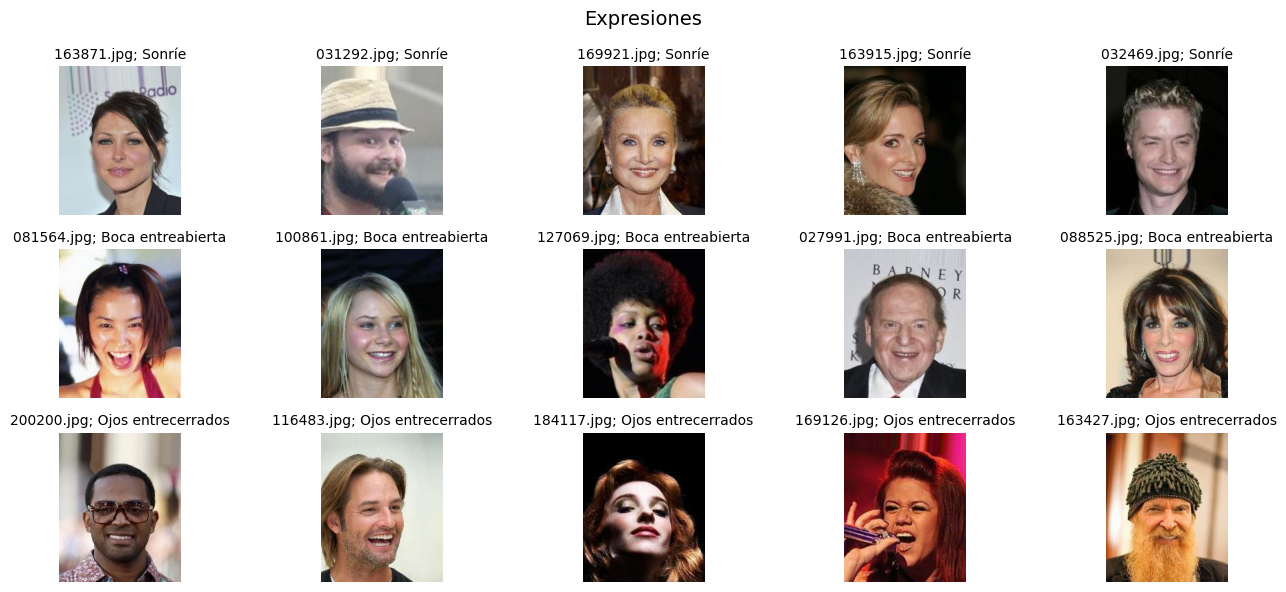

In [50]:
imgs, titles = [], []
for nombre in ["Sonríe", "Boca entreabierta", "Ojos entrecerrados"]:
    sub = df[atributos[nombre] == 1].sample(n=5, random_state=SEED)
    imgs += sub["src_path"].tolist()
    titles += [f"{i}; {nombre}" for i in sub["image_id"]]

show_images(imgs, titles=titles, ncols=5, size=(14, 6), suptitle="Expresiones")

## Detección y alineación (normalización)

Usamos InsightFace a través de `FaceAnalysis`, como en la notebook de la cátedra, cargando sólo los módulos de detección (SCRFD, `det_10g.onnx`) y reconocimiento (ArcFace, `w600k_r50.onnx`). Así, en una sola pasada obtenemos para cada rostro la caja, los 5 landmarks y su embedding, que usaremos más adelante para detectar duplicados y para el clustering exploratorio.

In [ ]:
# La primera vez descarga buffalo_l en models/buffalo_l/
face_app = load_face_app(root=MODELS_DIR.parent, det_size=DET_INPUT_SIZE, det_thresh=DET_SCORE_THRESHOLD)
(MODELS_DIR / "buffalo_l.zip").unlink(missing_ok=True)

In [52]:
prueba = df.sample(n=500, random_state=SEED)
imgs_prueba = [cv2.imread(p) for p in prueba["src_path"]]

for pad in [0.0, 0.25]:
    estados = [select_main_face(detect_faces(face_app, img, pad_ratio=pad), AMBIGUITY_RATIO)[1]
               for img in imgs_prueba]
    print(f"pad_ratio={pad}: {pd.Series(estados).value_counts().to_dict()}")

d:\Documentos\TUIA\5C\Computer Vision\tuia-face-recognition-app\.venv\Lib\site-packages\insightface\utils\face_align.py:23: FutureWarning: `estimate` is deprecated since version 0.26 and will be removed in version 2.2. Please use `SimilarityTransform.from_estimate` class constructor instead.
  tform.estimate(lmk, dst)


pad_ratio=0.0: {'unico': 491, 'principal': 9}
pad_ratio=0.25: {'unico': 492, 'principal': 8}


En `img_align_celeba` el rostro ocupa casi toda la imagen, mientras que los detectores se entrenan con rostros rodeados de fondo. Para verificar si eso afecta la detección, probamos sobre 500 imágenes agregar un borde negro del 25% del lado mayor antes de detectar. El detector encontró un rostro en las 500 imágenes en ambos casos, y la cantidad de imágenes con más de un rostro casi no cambia (9 sin borde frente a 8 con borde). Por eso no agregamos borde (`DET_PAD_RATIO = 0`).

In [56]:
if DETECTIONS_FILE.exists() and EMBBEDDINGS_FILE.exists():
    df_detections = pd.read_csv(DETECTIONS_FILE)
    embeddings = np.load(EMBBEDDINGS_FILE)
    print("Detecciones y embeddings leídos de disco")
else:
    rows, embeddings = [], []
    for image_id, path in tqdm(zip(df["image_id"], df["src_path"]), total=len(df), desc="detección y alineación"):
        img = cv2.imread(path)
        if img is None:
            rows.append({"image_id": image_id, "estado": "corrupta", "n_faces": 0})
            continue
        faces = detect_faces(face_app, img)
        idx, estado = select_main_face(faces, AMBIGUITY_RATIO)
        row = {"image_id": image_id, "estado": estado, "n_faces": len(faces)}
        if idx is not None:
            face = faces[idx]
            x1, y1, x2, y2 = face["bbox"]
            row.update({"det_score": face["det_score"], "det_x1": x1, "det_y1": y1, "det_x2": x2, "det_y2": y2})
            for k, (x, y) in enumerate(face["kps"]):
                row[f"kp{k}_x"], row[f"kp{k}_y"] = x, y
            aligned_path = ALIGNED_DIR / f"{Path(image_id).stem}.png"
            cv2.imwrite(str(aligned_path), align_face(img, face["kps"], FACE_SIZE))
            row["aligned_path"] = aligned_path.as_posix()
            row["emb_idx"] = len(embeddings)  # fila de este rostro en la matriz de embeddings
            embeddings.append(face["embedding"])
        rows.append(row)
    df_detections = pd.DataFrame(rows)
    embeddings = np.array(embeddings, dtype=np.float32)
    df_detections.to_csv(DETECTIONS_FILE, index=False)
    np.save(EMBBEDDINGS_FILE, embeddings)

df = df.drop(columns=[c for c in df_detections.columns if c != "image_id" and c in df.columns]).merge(df_detections, on="image_id", how="left")
print("Matriz de embeddings:", embeddings.shape)
df["estado"].value_counts()

detección y alineación: 100%|██████████| 26917/26917 [1:51:28<00:00,  4.02it/s]  


Matriz de embeddings: (26839, 512)


estado
unico         26436
principal       403
ambiguo          55
sin_rostro       23
Name: count, dtype: int64

La detección y alineación de las 26.917 imágenes tardó 111 minutos en CPU. Los resultados quedaron guardados en `data/processed/`. El detector encontró exactamente un rostro en el 98,2% (26.436) de las imágenes. En otro 1,5% (403) encontró varios, pero uno claramente más grande que el resto. En 55 imágenes (0,20%) el segundo rostro tiene al menos la mitad del área del primero, por lo que no es posible saber a cuál corresponde la etiqueta, y en 23 (0,09%) no detectó ningún rostro. Estas 78 imágenes se descartarán en el control de calidad. Ninguna imagen resultó ilegible.

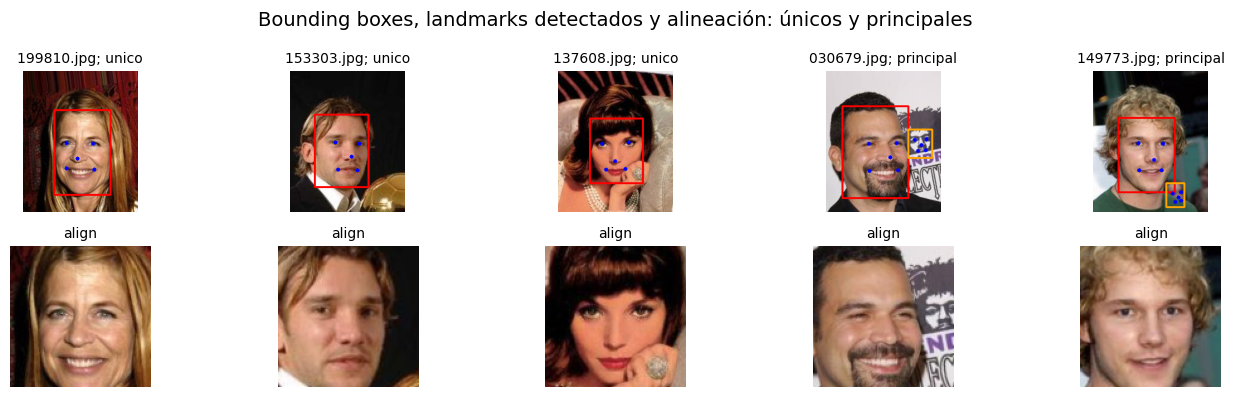

In [65]:
ejemplos = pd.concat([
    df[df["estado"] == "unico"].sample(3, random_state=SEED),
    df[df["estado"] == "principal"].sample(2, random_state=SEED),
])

antes, despues = [], []
for r in ejemplos.itertuples():
    img = cv2.imread(r.src_path)
    # Se vuelve a detectar para dibujar todas las caras, no sólo la elegida
    for i, face in enumerate(detect_faces(face_app, img)):
        x1, y1, x2, y2 = face["bbox"].astype(int)
        color = (0, 0, 255) if i == 0 else (0, 165, 255)  # BGR: rojo = elegida, naranja = otras
        cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
        for x, y in face["kps"].astype(int):
            cv2.circle(img, (x, y), 3, (255, 0, 0), -1)  # azul: landmarks
    antes.append(img)
    despues.append(cv2.imread(r.aligned_path))

show_images(
    antes + despues,
    titles=[f"{r.image_id}; {r.estado}" for r in ejemplos.itertuples()] + ["align"] * len(ejemplos),
    ncols=len(ejemplos), size=(14, 4),
    suptitle="Bounding boxes, landmarks detectados y alineación: únicos y principales",
)

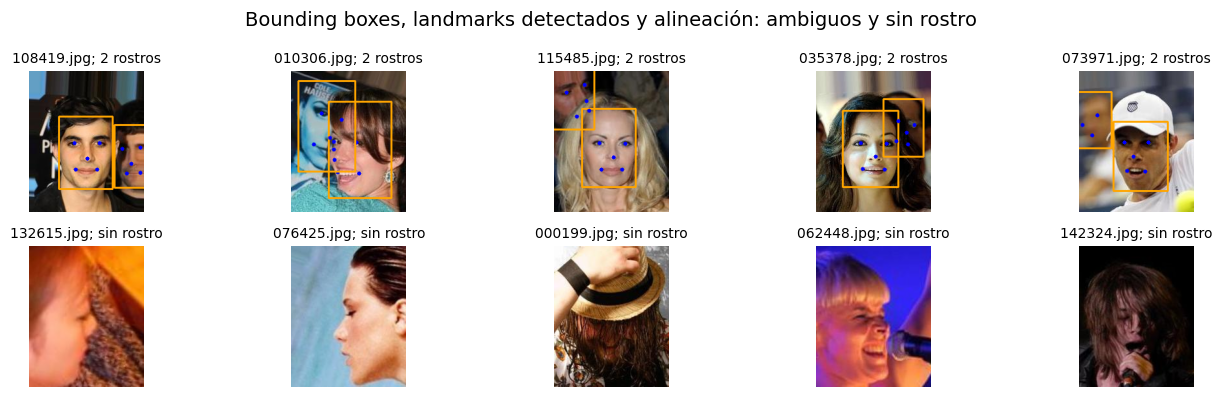

In [68]:
ambiguas = df[df["estado"] == "ambiguo"].sample(5, random_state=SEED)
sin_rostro = df[df["estado"] == "sin_rostro"].sample(5, random_state=SEED)

imgs, titles = [], []
for r in ambiguas.itertuples():
    img = cv2.imread(r.src_path)
    faces = detect_faces(face_app, img)
    for face in faces:
        x1, y1, x2, y2 = face["bbox"].astype(int)
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 165, 255), 2)  # naranja: ninguna elegida
        for x, y in face["kps"].astype(int):
            cv2.circle(img, (x, y), 3, (255, 0, 0), -1)
    imgs.append(img)
    titles.append(f"{r.image_id}; {len(faces)} rostros")

for r in sin_rostro.itertuples():
    imgs.append(r.src_path)
    titles.append(f"{r.image_id}; sin rostro")

show_images(imgs, titles=titles, size=(14, 4), suptitle="Bounding boxes, landmarks detectados y alineación: ambiguos y sin rostro")

En las imágenes ambiguas, el rostro etiquetado es casi siempre el que está centrado y el segundo es una persona cortada por el borde, alguien detrás o incluso una cara impresa en el fondo. Nuestra regla compara sólo el tamaño de los rostros y es conservadora: descarta imágenes que podrían recuperarse eligiendo el rostro más centrado. No la modificamos porque afecta a sólo 55 imágenes (0,2%) y porque ese criterio es específico para CelebA y no se trasladaría a fotos en general.

Las imágenes sin rostro detectado muestran las principales limitaciones del detector: perfiles completos, en los que no se pueden ubicar los 5 landmarks; oclusiones fuertes, por un sombrero, una mano o el pelo; y primeros planos recortados o desenfocados. La mayoría no servirían para entrenar aunque se detectara el rostro. Hay también algún falso negativo con el rostro visible, como el de iluminación violeta intensa con un micrófono delante. Es esperable que la app falle en casos similares, ya que usa el mismo detector.

## Control de calidad y limpieza

Aplicamos reglas de filtrado explícitas, con umbrales fijos e iguales para todas las imágenes. Las reglas se evalúan en orden, y cada imagen descartada se asigna a la primera regla que incumple, de modo que ninguna se cuenta dos veces. Los duplicados se evalúan al final, sólo entre las imágenes que superaron las reglas anteriores.

| Regla | Criterio | Motivo |
|---|---|---|
| R1. Archivo corrupto | `cv2.imread` no puede abrir el archivo | No se puede usar |
| R2. Sin rostro | El detector no encuentra ningún rostro | No hay nada que alinear |
| R3. Varios rostros ambiguos | El segundo rostro tiene al menos la mitad del área del primero | No se sabe a quién corresponde la etiqueta |
| R4. Rostro chico | El rostro medía menos de `MIN_FACE_SIZE` px en la foto original | Fue ampliado y tiene muy poco detalle real |
| R5. Sin color | Saturación media del rostro < 10 | En su mayoría son imágenes con filtros, no fotografías |
| R6. Borrosa | Varianza del Laplaciano del rostro alineado menor a un umbral | Sin bordes nítidos no hay rasgos para distinguir identidades |
| R7. Exposición extrema | Brillo del rostro muy bajo o muy alto, o contraste muy bajo | Rostro casi negro, quemado o sin relieve |
| R8. Casi-duplicado (misma identidad) | Similitud coseno entre embeddings > 0,95 | Se conserva una sola, evita fuga entre splits |
| R9. Casi-duplicado (distinta identidad) | Similitud coseno > 0,95 con una imagen de otra identidad | Conflicto de etiqueta, se descartan ambas |

### R1, R2, R3, R4 y R5

In [ ]:
reglas = [
    ("R1. Archivo corrupto", df["estado"] == "corrupta"),
    ("R2. Sin rostro", df["estado"] == "sin_rostro"),
    ("R3. Varios rostros ambiguos", df["estado"] == "ambiguo"),
    ("R4. Rostro chico", df["orig_bbox_width"] < MIN_FACE_SIZE),
    ("R5. Sin color", df["blanco_negro"]),
]

df["motivo_descarte"] = pd.Series(None, index=df.index, dtype="object")
incumplen = {}
for nombre, mask in reglas:
    incumplen[nombre] = int(mask.sum())
    df.loc[mask & df["motivo_descarte"].isna(), "motivo_descarte"] = nombre

tabla_qc = pd.DataFrame({
    "incumplen la regla": pd.Series(incumplen),
    "descartadas (en orden)": df["motivo_descarte"].value_counts(),
}).fillna(0).astype(int)

conservadas = df["motivo_descarte"].isna().sum()
print(f"Conservadas: {conservadas} de {len(df)} ({100 * conservadas / len(df):.2f}%)")
tabla_qc

### Borrosas o con exposición extrema (R6 y R7)

### Duplicados y casi-duplicados (R8 y R9)

## Clustering exploratorio

## Data augmentation

## Partición de datos (splits)

## Licencias y términos de uso

El uso del dataset **CelebA** está sujeto a los términos establecidos por el [Multimedia Laboratory (MMLAB)](https://mmlab.ie.cuhk.edu.hk/) de [The Chinese University of Hong Kong](https://www.cuhk.edu.hk/english/index.html):
- El dataset debe ser utilizado únicamente con fines de investigación académica no comercial.
- Se acuerda no reproducir, duplicar, copiar, vender ni explotar con fines comerciales ninguna porción de las imágenes ni de los datos derivados.
- Se acuerda no copiar, publicar ni redistribuir ninguna porción del dataset de manera pública. Se exceptua el uso interno entre miembros del proyecto.
- Todas las imágenes son obtenidas de Internet y no son propiedad de MMLAB.

```bibtex
@inproceedings{liu2015faceattributes,
  title = {Deep Learning Face Attributes in the Wild},
  author = {Liu, Ziwei and Luo, Ping and Wang, Xiaogang and Tang, Xiaoou},
  booktitle = {Proceedings of International Conference on Computer Vision (ICCV)},
  month = {December},
  year = {2015} 
}
```

## Ética y privacidad

Las imágenes de rostros humanos constituyen **datos biométricos**, los cuales son considerados datos personales e **información sensible** según la [Ley 25.326 de Protección de Datos Personales](https://www.argentina.gob.ar/normativa/nacional/norma-64790) en **Argentina**.
Para garantizar que el desarrollo de este trabajo práctico no vulnere privacidades ni infrinja ninguna ley, utilizamos las imágenes únicamente de **forma local** y **temporal**, **sin exponer material** en el repositorio público y **sin vincularlas con datos de identidad reales**. A su vez, el procesamiento de estos datos **no persigue fines de lucro**.

Se reconoce explícitamente que CelebA presenta **sesgos demográficos** inherentes a su origen (fotografías de celebridades públicas de la industria del entretenimiento), lo que genera una representación dispar en términos de rangos etarios, condiciones de iluminación, origen étnico y géneros frente a una población general. Esto puede impactar en la **capacidad de generalización** del modelo ante escenarios de **aplicación real**.